# Distributed MDO with DMDO: a Step-by-Step NHATC Tutorial

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L11/L11_DMDO_tutorial.ipynb)
### MECH 559 - Systems Optimization - L11
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

**DMDO** is a Python package that solves multidisciplinary design optimization problems with
**non-hierarchical analytical target cascading (NHATC)**: every discipline gets its own
optimizer, and an augmented Lagrangian coordinator (ADMM) drives their disagreements to zero.
This tutorial takes you from "what is a coupling variable?" to setting up your own
multi-discipline problem, one level at a time. Each level adds **one** new idea and ends with a
check that the answer is right.

## Learning objectives

By the end, students should be able to:

1. Build DMDO problems from the compact table to executable subproblem objects.
2. Configure NHATC coordination settings (including penalties, multipliers, and updates).
3. Compare solver and coordination options on benchmark MDO problems.
4. Run DMDO from both Python objects and YAML workflows.

| Level | You learn to | Problem |
|---|---|---|
| 1 | describe a problem with the **compact table**, build every DMDO object by hand, run, read results | lecture's running example |
| 2 | use a builder function; choose the subproblem **solver**; tune the **coordination** ($\beta$, weight update) | running example |
| 3 | set up a classic benchmark with two **shared** variables and **feedback** coupling | Sellar problem |
| 4 | handle **three** subproblems, a variable shared by all, and **ring** coupling | three-discipline ring |
| 5 | describe a problem in a **YAML file** and run it with `DMDO.main` | running example |
| 6 | avoid the common pitfalls; set up **your own** problem | checklist and exercises |

**Before you start.** This notebook assumes the ideas of the three companion notebooks:
`L11_multidisciplinary_analysis` (MDA), `L11_monolithic_mdo_mdf_idf` (MDF/IDF and the reference
optimum $f^* \approx 4.989$) and `L11_atc_nhatc_from_scratch` (the penalty and its updates).
You can follow this one on its own, but those explain *why* things work.

**Version.** We use the published package from PyPI, **DMDO 2604.0**. Install it once in the
course environment with `pip install DMDO==2604.0` (uncomment the next cell to do it from here).

In [1]:
# %pip install DMDO==2604.0

In [2]:
import contextlib
import io
import os
import tempfile
import time
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# DMDO 2604.0 creates a "data/logs/..." folder in the current directory when it is imported, and
# writes logs and checkpoints while it runs. We do all of that in a temporary folder so the
# course folder stays clean.
WORK_DIR = tempfile.mkdtemp(prefix="dmdo_tutorial_")
_cwd = os.getcwd()
os.chdir(WORK_DIR)
from DMDO import (ADMM, COUPLING_TYPE, DA, MDA, MDO, MDO_ARCHITECTURE, PSIZE_UPDATE,  # noqa: E402
                  SubProblem, variableData, w_scheme, main)
os.chdir(_cwd)

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = ["#1D5FA8", "#D1495B", "#2A9D5C", "#EDAE49", "#7B2CBF"]
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
print(f"DMDO {version('DMDO')}, OMADS {version('OMADS')}; scratch folder: {WORK_DIR}")

DMDO 2604.0, OMADS 2610; scratch folder: C:\Users\ahbay\AppData\Local\Temp\dmdo_tutorial_g9_fqhb1


---
# Level 1: the running example, built by hand

## 1.1 The problem, seen as two teams

$$
\min_{u, v, w}\ u + v + a + b \quad \text{s.t.}\quad w + b - 10 \le 0,
\qquad a = \log u + \log v + \log b, \qquad b = u^{-1} + w^{-1} + a^{-1}
$$

Two disciplines (two "teams"), each with its own **subproblem** (SP):

- **SP 1** owns discipline 1, which computes $a$ from $u, v, b$. It also owns the design
  variable $v$ and the objective.
- **SP 2** owns discipline 2, which computes $b$ from $u, w, a$. It owns $w$ and the constraint.

$u$ is used by both teams, $a$ goes from SP 1 to SP 2, and $b$ from SP 2 to SP 1.

## 1.2 The compact table: the heart of a DMDO model

DMDO describes the problem with **one row per variable per subproblem** (the table on the
slide *Implementation based on problem structure*). A variable that two subproblems both use
appears **twice**, once in each, and the `link` column says which subproblem holds the other
copy. The `coupling` column says what kind of variable each row is:

| code | DMDO name | meaning in *this* subproblem |
|---|---|---|
| `u` | `UNCOUPLED` | a **local** design variable, nobody else uses it |
| `s` | `SHARED` | a design variable that other subproblems also use: this row is **my copy** |
| `ff` | `FEEDFORWARD` | a coupling variable that **I compute** and send to the linked subproblem |
| `fb` | `FEEDBACK` | a coupling variable that **I receive**: this row is my **target** for it |

NHATC then adds one consistency constraint per linked pair of rows, e.g. "SP 1's copy of $u$
= SP 2's copy of $u$" and "SP 2's target for $a$ = the $a$ computed by SP 1".

In [3]:
running_table = pd.DataFrame(
    [("u", 1, 2, "s", 1e-3, 1.0, 10.0),
     ("v", 1, None, "u", 1e-3, 1.0, 10.0),
     ("a", 1, 2, "ff", 0.1, 1.0, 10.0),
     ("b", 1, 2, "fb", 0.1, 1.0, 10.0),
     ("u", 2, 1, "s", 1e-3, 1.0, 10.0),
     ("w", 2, None, "u", 1e-3, 1.0, 10.0),
     ("a", 2, 1, "fb", 0.1, 1.0, 10.0),
     ("b", 2, 1, "ff", 0.1, 1.0, 10.0)],
    columns=["name", "subproblem", "link", "coupling", "lb", "baseline", "ub"],
    index=pd.RangeIndex(1, 9, name="variable #"))
running_table

,name,subproblem,link,coupling,lb,baseline,ub
variable #,,,,,,,
1,u,1,2,s,0.001,1,10
2,v,1,NaN,u,0.001,1,10
3,a,1,2,ff,0.1,1,10
4,b,1,2,fb,0.1,1,10
5,u,2,1,s,0.001,1,10
6,w,2,NaN,u,0.001,1,10
7,a,2,1,fb,0.1,1,10
8,b,2,1,ff,0.1,1,10


Read it row by row: row 3 says "SP 1 **computes** $a$ and sends it to SP 2"; row 7 says
"SP 2 **receives** $a$ from SP 1 and keeps a target for it". Rows 3 and 7 form one consistency
constraint.

Two details matter more than they look:

- **Bounds on coupling variables are constraints.** DMDO adds $lb \le a \le ub$ to the
  subproblem that computes $a$. We use $a, b \ge 0.1$: as the MDF notebook showed, this MDA has
  a non-physical branch with $a < 0$, and the bound keeps us off it.
- **The baseline** is the starting point of every copy and target.

## 1.3 From the table to DMDO variables

Each row becomes a `variableData` object. The `index` must be the row number (starting at 1):
DMDO uses it to find the variable in its master list. `scaling` is the range $ub - lb$; we will
use it to scale the inconsistencies.

In [4]:
CODES = {"s": COUPLING_TYPE.SHARED, "u": COUPLING_TYPE.UNCOUPLED,
         "ff": COUPLING_TYPE.FEEDFORWARD, "fb": COUPLING_TYPE.FEEDBACK}


def make_variables(table):
    """One variableData per row of a compact table (index = row number, starting at 1)."""
    V = []
    for i, r in enumerate(table.itertuples(index=False), start=1):
        link = None if r.link is None or (isinstance(r.link, float) and np.isnan(r.link)) else r.link
        link = [int(k) for k in link] if isinstance(link, (list, tuple)) else (None if link is None else int(link))
        V.append(variableData(name=r.name, sp_index=int(r.subproblem), coupling_type=CODES[r.coupling],
                              link=link, dim=1, value=float(r.baseline), baseline=float(r.baseline),
                              scaling=float(r.ub - r.lb), lb=float(r.lb), ub=float(r.ub), type="REAL", index=i))
    return V


V = make_variables(running_table)
V[2]

variableData(name='a', sp_index=1, coupling_type=<COUPLING_TYPE.FEEDFORWARD: 3>, link=2, dim=1, value=1.0, baseline=1.0, scaling=9.9, lb=0.1, ub=10.0, type='REAL', index=3, set=None, cond_on=None)

## 1.4 Disciplinary analyses

A disciplinary analysis is any Python function that takes a **list** of input values and
returns a **list** of outputs. In real life it would call a CFD or FEA code. DMDO wraps it in a
`DA` object that knows which variables are its inputs and outputs.

In [5]:
def analysis_1(x):
    """Discipline 1: x = [u, v, b] -> [a]."""
    u, v, b = x
    return [np.log(u) + np.log(v) + np.log(b)]


def analysis_2(x):
    """Discipline 2: x = [u, w, a] -> [b]."""
    u, w, a = x
    return [1.0 / u + 1.0 / w + 1.0 / a]


da1 = DA(inputs=[V[0], V[1], V[3]], outputs=[V[2]], blackbox=analysis_1, links=[2],
         coupling_type=COUPLING_TYPE.FEEDFORWARD)
da2 = DA(inputs=[V[4], V[5], V[6]], outputs=[V[7]], blackbox=analysis_2, links=[1],
         coupling_type=COUPLING_TYPE.FEEDFORWARD)

print("DA 1 inputs :", [(v.name, v.value) for v in da1.inputs])
print("DA 1 output :", da1.run(), " (log 1 + log 1 + log 1 = 0)")

DA 1 inputs : [('u', 1.0), ('v', 1.0), ('b', 1.0)]
DA 1 output : [0.0]  (log 1 + log 1 + log 1 = 0)


Each subproblem runs its analyses through an `MDA` object. Here each subproblem has a single
discipline, so the "MDA" is just one analysis; a subproblem that owned two tightly coupled
disciplines could converge them internally.

In [6]:
mda1 = MDA(nAnalyses=1, analyses=[da1], variables=[V[0], V[1], V[3]], responses=[V[2]])
mda2 = MDA(nAnalyses=1, analyses=[da2], variables=[V[4], V[5], V[6]], responses=[V[7]])

## 1.5 Subproblem objectives and constraints

Each subproblem has an `opt(x, y, *args)` function:

- `x` holds the subproblem's **inputs** in the order you listed them (local, shared and
  feedback variables: here $[u, v, b]$ for SP 1);
- `y` holds the outputs of its analyses (here $[a]$);
- it returns `[f, [g_1, ..., g_m]]` with $g_j \le 0$ feasible. A subproblem with no
  constraint returns `[f, [0.0]]`, and one with no objective term returns `0.0` for $f$.

DMDO adds the NHATC penalty to `f` itself; you write only the physics.

In [7]:
def objective_1(x, y, *args):
    u, v, b = x
    a = y[0]
    return [u + v + a + b, [0.0]]          # SP 1 carries the whole objective, no constraint


def objective_2(x, y, *args):
    u, w, a = x
    b = y[0]
    return [0.0, [w + b - 10.0]]           # SP 2 carries the constraint w + b <= 10

## 1.6 Coordinator, subproblems and the MDO

- `ADMM` is the coordinator: penalty growth `beta`, reduction factor `gamma` (as in the slides),
  weight-update `M_update_scheme`, outer-iteration `budget`, and the `scaling` of each
  inconsistency. We scale every inconsistency by $1/(ub - lb)$, so that a disagreement of 1% of
  a variable's range counts the same for every variable.
- `SubProblem` ties together its variables, its MDA, its `opt` function and its **solver**.
  We start with `solver="scipy"` (SLSQP), the fastest option for smooth problems; Level 2
  compares it with the derivative-free OMADS solvers.
- `MDO` collects everything. `inc_stop` stops the outer loop when the largest scaled
  inconsistency drops below it.

In [8]:
SCIPY_SETTINGS = {"method": "SLSQP", "options": {"disp": False, "maxiter": 200}, "is_con": True, "tol": 1e-8}

coordinator = ADMM(beta=1.3, gamma=0.5, nsp=2, budget=50, index_of_master_SP=1, display=False,
                   scaling=[1.0 / v.scaling for v in V], mode="serial",
                   M_update_scheme=w_scheme.MEDIAN, store_q_io=False)

common = dict(coordination=coordinator, fmin_nop=np.inf, budget=150, display=False, psize=1.0,
              pupdate=PSIZE_UPDATE.LAST, solver="scipy")
sp1 = SubProblem(nv=3, index=1, vars=[V[0], V[1], V[3]], resps=[V[2]], is_main=1, analysis=mda1,
                 opt=objective_1, scipy=dict(SCIPY_SETTINGS), **common)
sp2 = SubProblem(nv=3, index=2, vars=[V[4], V[5], V[6]], resps=[V[7]], is_main=0, analysis=mda2,
                 opt=objective_2, scipy=dict(SCIPY_SETTINGS), **common)

running_mdo = MDO(Architecture=MDO_ARCHITECTURE.IDF, Coordinator=coordinator, subProblems=[sp1, sp2],
                  variables=V, responses=[V[2], V[7]], fmin=np.inf, hmin=np.inf, display=True,
                  inc_stop=1e-6, stop="Iteration budget exhausted", tab_inc=[], noprogress_stop=100)

## 1.7 Run it and read the results

`MDO.run(file=...)` writes its logs and a CSV file `Coordination_history.out` (one row per outer
iteration) next to `file`. The small helper below runs quietly in its own scratch folder and
returns that history as a DataFrame.

In [9]:
def run(mdo, name="run"):
    """Run an MDO quietly in a fresh scratch folder. Returns (history DataFrame, seconds)."""
    out_dir = tempfile.mkdtemp(prefix=f"{name}_", dir=WORK_DIR)
    tic = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mdo.run(file=os.path.join(out_dir, f"{name}.out"), mode="serial")
    seconds = time.perf_counter() - tic
    hist = pd.read_csv(os.path.join(out_dir, "Coordination_history.out"), skipinitialspace=True)
    hist.columns = [c.strip() for c in hist.columns]
    hist = hist.rename(columns={"Iteration #": "iteration", "Max. inconsistency": "max inconsistency",
                                "Maximum penalty": "max w"}).set_index("iteration")
    return hist, seconds


def values(mdo):
    """Final value of every copy/target, keyed 'name_subproblem'."""
    return {f"{v.name}_{v.sp_index}": float(v.value) for v in mdo.Coordinator.master_vars}


def max_inconsistency(mdo):
    return float(np.max(np.abs(np.asarray(mdo.Coordinator.q, dtype=float))))


hist, seconds = run(running_mdo, "running")
print(f"stopped: '{running_mdo.stop}' after {len(hist)} outer iterations ({seconds:.1f} s)")
pd.Series(values(running_mdo), name="final value").to_frame().T

stopped: 'Max inconsitency is below stopping threshold' after 24 outer iterations (3.1 s)


,u_1,v_1,a_1,b_1,u_2,w_2,a_2,b_2
final value,1.31462,0.601957,0.652212,2.42597,1.31463,7.57404,0.652204,2.42596


Every pair of copies now agrees: $u_1 = u_2$, $a_1 = a_2$, $b_1 = b_2$. **Always verify** the
result yourself, with the original (not the decomposed) problem: recompute the disciplines at
the final design, check consistency, feasibility and the objective, and compare with a
reference when you have one.

In [10]:
F_REF_RUNNING = 4.98933            # monolithic optimum (MDF/IDF notebook)


def check_running(mdo):
    x = values(mdo)
    u, v, w = x["u_1"], x["v_1"], x["w_2"]
    a = analysis_1([u, v, x["b_1"]])[0]          # recompute the disciplines from the final design
    b = analysis_2([u, w, x["a_2"]])[0]
    return {"f": u + v + a + b, "gap to reference": u + v + a + b - F_REF_RUNNING, "g = w + b - 10": w + b - 10,
            "|a - a target|": abs(a - x["a_2"]), "|b - b target|": abs(b - x["b_1"]),
            "|u_1 - u_2|": abs(u - x["u_2"]),
            "max inconsistency": max(abs(a - x["a_2"]), abs(b - x["b_1"]), abs(u - x["u_2"]))}


pd.Series(check_running(running_mdo)).to_frame("Level 1").T

,f,gap to reference,g = w + b - 10,|a - a target|,|b - b target|,|u_1 - u_2|,max inconsistency
Level 1,4.99476,0.00542955,5.02858e-06,8.11766e-06,8.43499e-07,8.81853e-06,8.81853e-06


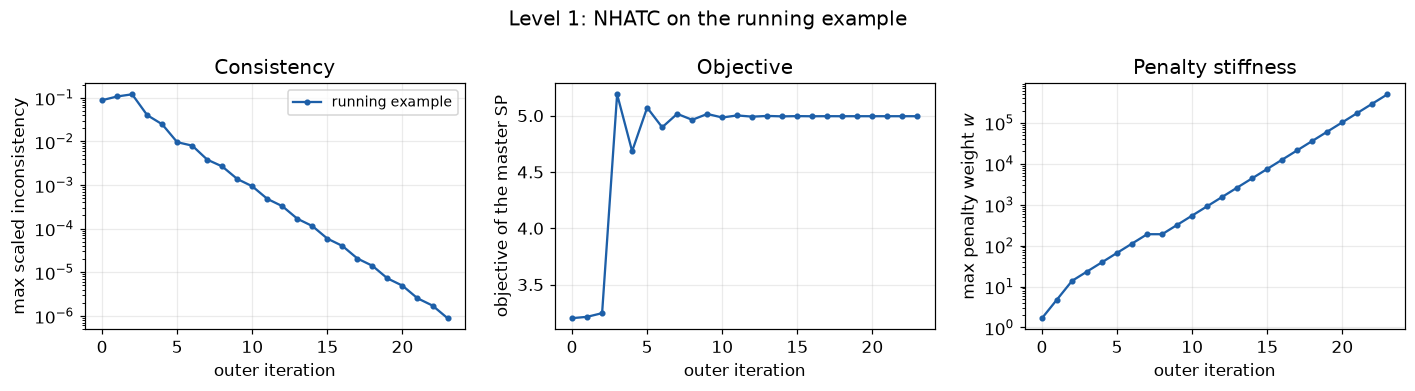

In [11]:
def plot_histories(runs, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for (label, h), c in zip(runs.items(), COLORS * 3):
        axes[0].semilogy(h.index, h["max inconsistency"], "o-", ms=3, color=c, label=label)
        axes[1].plot(h.index, h["Objective"], "o-", ms=3, color=c, label=label)
        axes[2].semilogy(h.index, h["max w"], "o-", ms=3, color=c, label=label)
    axes[0].set(xlabel="outer iteration", ylabel="max scaled inconsistency", title="Consistency")
    axes[1].set(xlabel="outer iteration", ylabel="objective of the master SP", title="Objective")
    axes[2].set(xlabel="outer iteration", ylabel="max penalty weight $w$", title="Penalty stiffness")
    axes[0].legend(fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_histories({"running example": hist}, "Level 1: NHATC on the running example")

The same three curves as in the from-scratch notebook: the inconsistency falls by orders of
magnitude, the objective settles, and the penalty weights grow geometrically. The
**Objective** column is the objective of the *master* subproblem (`index_of_master_SP`); it is
the full objective here only because SP 1 carries all of it.

> **Checkpoint 1.** (a) Which rows of the table form the consistency constraint for $b$?
> (b) Why does `objective_2` return `0.0` as its objective? (c) What would happen without the
> bound $a \ge 0.1$?
>
> *Answers:* (a) rows 4 (SP 1's target) and 8 (SP 2's response). (b) SP 2 carries no part of
> $f$; its job is the constraint and its consistency penalty, which DMDO adds. (c) SP 1 could
> slip onto the non-physical branch $a < 0$, where $f$ is unbounded below.

---
# Level 2: a builder, solvers and coordination knobs

## 2.1 A builder function

Section 1.6 is the same for every problem, so we wrap it in a function. A problem is now a
compact table plus one small dictionary per subproblem: which rows are its inputs and outputs,
its analysis, and its `opt` function.

In [12]:
def build_mdo(table, specs, master=1, beta=1.3, gamma=0.5, budget=50, solver="scipy",
              scheme=w_scheme.MEDIAN, inc_stop=1e-6, sp_budget=150):
    """Assemble an NHATC problem from a compact table and one spec per subproblem.

    spec = dict(index=..., inputs=[row numbers], outputs=[row numbers], analysis=func, opt=func)
    solver: "scipy" (SLSQP), "poll" or "mads" (OMADS, derivative-free).
    """
    V = make_variables(table)
    coord = ADMM(beta=beta, gamma=gamma, nsp=len(specs), budget=budget, index_of_master_SP=master,
                 display=False, scaling=[1.0 / v.scaling for v in V], mode="serial",
                 M_update_scheme=scheme, store_q_io=False)
    sps, responses = [], []
    for s in specs:
        ins, outs = [V[i - 1] for i in s["inputs"]], [V[i - 1] for i in s["outputs"]]
        others = [t["index"] for t in specs if t["index"] != s["index"]]
        da = DA(inputs=ins, outputs=outs, blackbox=s["analysis"], links=others,
                coupling_type=COUPLING_TYPE.FEEDFORWARD)
        sps.append(SubProblem(nv=len(ins), index=s["index"], vars=ins, resps=outs, is_main=int(s["index"] == master),
                              analysis=MDA(nAnalyses=1, analyses=[da], variables=ins, responses=outs),
                              coordination=coord, opt=s["opt"], fmin_nop=np.inf, budget=sp_budget, display=False,
                              psize=1.0, pupdate=PSIZE_UPDATE.LAST, solver=solver,
                              scipy=dict(SCIPY_SETTINGS) if solver == "scipy" else None))
        responses += outs
    return MDO(Architecture=MDO_ARCHITECTURE.IDF, Coordinator=coord, subProblems=sps, variables=V,
               responses=responses, fmin=np.inf, hmin=np.inf, display=True, inc_stop=inc_stop,
               stop="Iteration budget exhausted", tab_inc=[], noprogress_stop=100)


RUNNING_SPECS = [dict(index=1, inputs=[1, 2, 4], outputs=[3], analysis=analysis_1, opt=objective_1),
                 dict(index=2, inputs=[5, 6, 7], outputs=[8], analysis=analysis_2, opt=objective_2)]

mdo = build_mdo(running_table, RUNNING_SPECS)
h, s = run(mdo, "builder")
pd.Series(check_running(mdo)).to_frame("builder").T

,f,gap to reference,g = w + b - 10,|a - a target|,|b - b target|,|u_1 - u_2|,max inconsistency
builder,4.99476,0.00542955,5.02858e-06,8.11766e-06,8.43499e-07,8.81853e-06,8.81853e-06


Same answer as Level 1, in three lines.

## 2.2 Which solver for the subproblems?

Each subproblem is an ordinary optimization problem, and DMDO can solve it with:

- `"scipy"`: SLSQP, gradient-based (finite differences). Fast and accurate for smooth physics.
- `"poll"`: the OMADS poll step only (derivative-free, from L10).
- `"mads"`: OMADS with search and poll (derivative-free).

Use a derivative-free solver when the disciplines are **noisy, nonsmooth or may crash**, which
is common with simulation codes. The cell below takes about a minute.

In [13]:
solver_runs, rows = {}, []
for solver in ["scipy", "poll", "mads"]:
    mdo = build_mdo(running_table, RUNNING_SPECS, solver=solver)
    h, s = run(mdo, solver)
    solver_runs[solver] = h
    rows.append({"solver": solver, "seconds": s, "outer iterations": len(h), "stop": mdo.stop,
                 **check_running(mdo)})
pd.DataFrame(rows).set_index("solver")

,seconds,outer iterations,stop,f,gap to reference,g = w + b - 10,|a - a target|,|b - b target|,|u_1 - u_2|,max inconsistency
solver,,,,,,,,,,
scipy,3.04543,24,Max inconsitency is below stopping threshold,4.99476,0.00542955,5.02858e-06,8.11766e-06,8.43499e-07,8.81853e-06,8.81853e-06
poll,30.171,50,Iteration budget exhausted,4.99284,0.003513,-0.0023257,5.51541e-05,0.000213793,0.000118293,0.000213793
mads,32.0624,50,Iteration budget exhausted,4.95352,-0.0358132,-2.49789,0.0669312,0.0638129,0.000145723,0.0669312


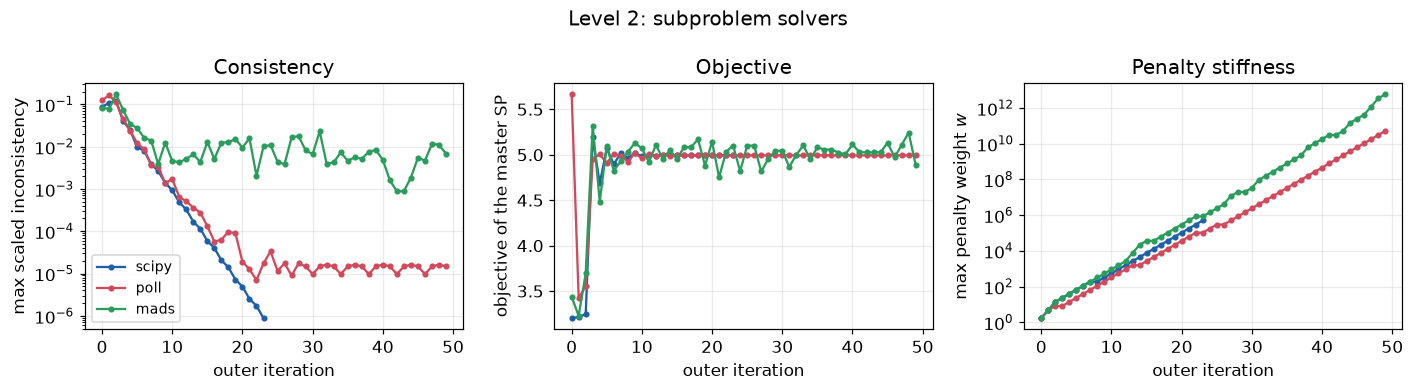

In [14]:
plot_histories(solver_runs, "Level 2: subproblem solvers")

Read the table **column by column**, not just the `f` column:

- `scipy` stopped because it reached consistency, in a few seconds, close to the reference.
- Both OMADS runs used their whole budget of 50 outer iterations ("Iteration budget
  exhausted"); each outer iteration spends a fixed number of evaluations per subproblem, so
  they are about ten times slower. `poll` ended nearly consistent and close to the reference.
- `mads` reports an $f$ **below** the reference optimum. That is not a better design: its
  inconsistency columns show that its disciplines still disagree (and its constraint is far
  from active). An inconsistent design is not a design, whatever its $f$.

Rule of thumb: **use `scipy` when the analyses are smooth, OMADS when they are blackboxes, and
always read the consistency and the stop reason before the objective.**

## 2.3 Coordination knobs

Two parameters of the coordinator control how quickly the penalty stiffens:

- `beta` ($\beta$): the growth factor of a weight whose inconsistency did not shrink enough;
- `M_update_scheme`: which weights may grow. `MEDIAN` grows only the weights of the
  inconsistencies above the median, `NORMAL` grows every stalled weight (the textbook rule from
  the slides), `MAX` only the largest, `RANK` in proportion to the rank of the inconsistency.

In [15]:
rows, beta_runs = [], {}
for beta in [1.1, 1.3, 2.0, 3.0]:
    mdo = build_mdo(running_table, RUNNING_SPECS, beta=beta)
    h, s = run(mdo, f"beta{beta}")
    beta_runs[f"beta = {beta}"] = h
    rows.append({"beta": beta, "outer iterations": len(h), "seconds": s, **check_running(mdo)})
pd.DataFrame(rows).set_index("beta")[["outer iterations", "seconds", "max inconsistency", "f", "gap to reference",
                                      "g = w + b - 10"]]

,outer iterations,seconds,max inconsistency,f,gap to reference,g = w + b - 10
beta,,,,,,
1.1,46,17.5579,3.76758e-06,4.99013,0.000802273,-0.0610111
1.3,24,3.09553,8.81853e-06,4.99476,0.00542955,5.02858e-06
2,14,1.58327,9.31334e-06,5.59487,0.605535,-6.23367e-08
3,50,2.45649,0.000104278,5.2274,0.238065,-4.74649e-05


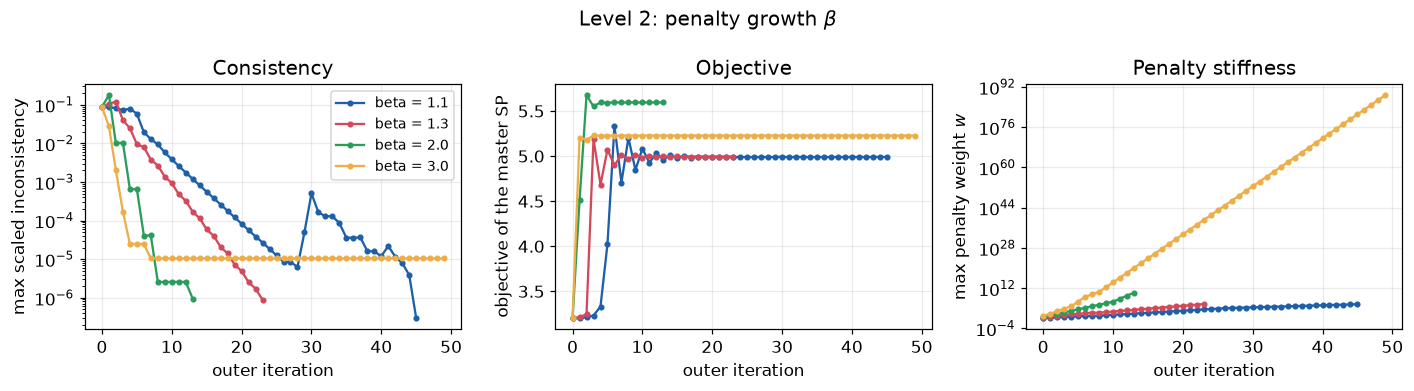

In [16]:
plot_histories(beta_runs, r"Level 2: penalty growth $\beta$")

From $\beta = 1.1$ to $\beta = 2$ you see the trade-off from the from-scratch notebook: a
larger $\beta$ reaches consistency in fewer outer iterations, but the subproblems stop
improving the objective once the penalty dominates, so the design ends further from the
optimum. $\beta = 3$ goes too far: the penalty becomes so stiff so early that the subproblems
become badly conditioned, and the run stalls until its budget runs out. There is a useful
range for $\beta$, and it depends on the problem.

In [17]:
rows = []
for scheme in [w_scheme.MEDIAN, w_scheme.NORMAL, w_scheme.MAX, w_scheme.RANK]:
    mdo = build_mdo(running_table, RUNNING_SPECS, scheme=scheme)
    h, s = run(mdo, scheme.name)
    rows.append({"scheme": scheme.name, "outer iterations": len(h), **check_running(mdo)})
pd.DataFrame(rows).set_index("scheme")[["outer iterations", "max inconsistency", "f", "gap to reference",
                                        "g = w + b - 10"]]

,outer iterations,max inconsistency,f,gap to reference,g = w + b - 10
scheme,,,,,
MEDIAN,24,8.81853e-06,4.99476,0.00542955,5.02858e-06
NORMAL,24,8.02808e-06,4.99364,0.00430895,1.76522e-06
MAX,26,9.17979e-06,4.99948,0.0101469,-0.000980328
RANK,50,1.1913,3.56701,-1.42232,-2.51159e-06


`NORMAL`, `MEDIAN` and `MAX` all converge here. `RANK` reports a much lower $f$, but look at its
**max inconsistency** and iteration count: it used its whole budget without reaching
consistency, so its design is not a real design and its $f$ means nothing.

> **Checkpoint 2.** Your disciplines are a commercial CFD code (no gradients, occasionally
> crashes) and an in-house beam model (smooth, fast). Which solver would you give each
> subproblem? *Answer:* `mads` for the CFD subproblem, `scipy` for the beam. DMDO lets each
> subproblem have its own solver: pass a different `solver` to each `SubProblem`.

---
# Level 3: the Sellar problem (shared variables and feedback coupling)

The Sellar problem is the classic two-discipline MDO benchmark:

$$
\begin{aligned}
\min_{x, z_1, z_2}\ & x^2 + z_2 + y_1 + e^{-y_2} \\
\text{s.t.}\ & g_1 = 3.16 - y_1 \le 0, \qquad g_2 = y_2 - 24 \le 0, \\
& 0 \le x \le 10, \quad -10 \le z_1 \le 10, \quad 0 \le z_2 \le 10, \\
\text{where}\ & y_1 = z_1^2 + z_2 + x - 0.2\,y_2 \quad \text{(discipline 1)}, \qquad
                y_2 = \sqrt{y_1} + z_1 + z_2 \quad \text{(discipline 2)}.
\end{aligned}
$$

Its optimum is known: $f^* = 3.18339$ at $z_1 = 1.9776$, $z_2 = 0$, $x = 0$, with $y_1 = 3.16$
(so $g_1$ is active) and $y_2 = 3.7553$.

What is new: **two** shared variables ($z_1, z_2$), and natural bounds on the coupling
variables. Since $g_1$ requires $y_1 \ge 3.16$, we use 3.16 as the lower bound of $y_1$; DMDO
then enforces it in the subproblem that computes $y_1$.

**Your turn first.** Before reading the next cell, write the compact table on paper: which
subproblem owns $x$? Which rows are `s`, `ff`, `fb`?

In [18]:
sellar_table = pd.DataFrame(
    [("x", 1, None, "u", 0.0, 1.0, 10.0),
     ("z1", 1, 2, "s", -10.0, 5.0, 10.0),
     ("z2", 1, 2, "s", 0.0, 2.0, 10.0),
     ("y1", 1, 2, "ff", 3.16, 3.16, 115.2),
     ("y2", 1, 2, "fb", 1.7776, 2.0, 24.0),
     ("z1", 2, 1, "s", -10.0, 5.0, 10.0),
     ("z2", 2, 1, "s", 0.0, 2.0, 10.0),
     ("y1", 2, 1, "fb", 3.16, 3.16, 115.2),
     ("y2", 2, 1, "ff", 1.7776, 2.0, 24.0)],
    columns=["name", "subproblem", "link", "coupling", "lb", "baseline", "ub"],
    index=pd.RangeIndex(1, 10, name="variable #"))


def sellar_analysis_1(x):            # x = [x, z1, z2, y2] -> [y1]
    return [x[1] ** 2 + x[2] + x[0] - 0.2 * x[3]]


def sellar_analysis_2(x):            # x = [z1, z2, y1] -> [y2]
    return [np.sqrt(max(x[2], 0.0)) + x[0] + x[1]]


def sellar_objective_1(x, y, *args):
    xx, z1, z2, y2 = x
    y1 = y[0]
    return [xx ** 2 + z2 + y1 + np.exp(-y2), [3.16 - y1]]


def sellar_objective_2(x, y, *args):
    return [0.0, [y[0] - 24.0]]


SELLAR_SPECS = [dict(index=1, inputs=[1, 2, 3, 5], outputs=[4], analysis=sellar_analysis_1, opt=sellar_objective_1),
                dict(index=2, inputs=[6, 7, 8], outputs=[9], analysis=sellar_analysis_2, opt=sellar_objective_2)]
F_REF_SELLAR = 3.18339


def check_sellar(mdo):
    x = values(mdo)
    xx, z1, z2 = x["x_1"], x["z1_1"], x["z2_1"]
    y1 = sellar_analysis_1([xx, z1, z2, x["y2_1"]])[0]
    y2 = sellar_analysis_2([z1, z2, x["y1_2"]])[0]
    f = xx ** 2 + z2 + y1 + np.exp(-y2)
    return {"f": f, "gap to reference": f - F_REF_SELLAR, "x": xx, "z1": z1, "z2": z2, "y1": y1, "y2": y2,
            "max |inconsistency|": max(abs(y1 - x["y1_2"]), abs(y2 - x["y2_1"]), abs(z1 - x["z1_2"]), abs(z2 - x["z2_2"]))}


sellar_table

,name,subproblem,link,coupling,lb,baseline,ub
variable #,,,,,,,
1,x,1,NaN,u,0,1,10
2,z1,1,2,s,-10,5,10
3,z2,1,2,s,0,2,10
4,y1,1,2,ff,3.16,3.16,115.2
5,y2,1,2,fb,1.7776,2,24
6,z1,2,1,s,-10,5,10
7,z2,2,1,s,0,2,10
8,y1,2,1,fb,3.16,3.16,115.2
9,y2,2,1,ff,1.7776,2,24


In [19]:
rows, sellar_runs = [], {}
for label, kw in {"default (MEDIAN, beta 1.3)": {}, "NORMAL scheme": {"scheme": w_scheme.NORMAL},
                  "MEDIAN, beta 1.1": {"beta": 1.1}, "MEDIAN, beta 2.0": {"beta": 2.0}}.items():
    mdo = build_mdo(sellar_table, SELLAR_SPECS, budget=60, **kw)
    h, s = run(mdo, "sellar")
    sellar_runs[label] = h
    rows.append({"settings": label, "outer iterations": len(h), "seconds": s, **check_sellar(mdo)})
pd.DataFrame(rows).set_index("settings")

,outer iterations,seconds,f,gap to reference,x,z1,z2,y1,y2,max |inconsistency|
settings,,,,,,,,,,
"default (MEDIAN, beta 1.3)",26,4.48043,3.23293,0.0495393,0.00330666,1.98691,0.00796691,3.20223,3.78434,4.19879e-05
NORMAL scheme,19,2.19535,3.18339,3.97329e-06,7.92405e-15,1.97764,9.5764e-15,3.16,3.75528,1.7372e-05
"MEDIAN, beta 1.1",31,3.23491,3.18347,8.07608e-05,0.00618487,1.97599,1.33271e-14,3.16,3.75363,2.02144e-05
"MEDIAN, beta 2.0",12,2.1017,4.14098,0.957593,0.10673,2.19519,0.0185644,4.09659,4.23775,1.87479e-05


All four runs end **consistent**, but not equally good: only some reach the known optimum.
This is the most important habit of this tutorial: **a converged distributed run is not
necessarily an optimal one.** Compare with a reference (known optimum, or a monolithic run
as in the MDF/IDF notebook) before you trust the settings, then reuse those settings on
similar problems.

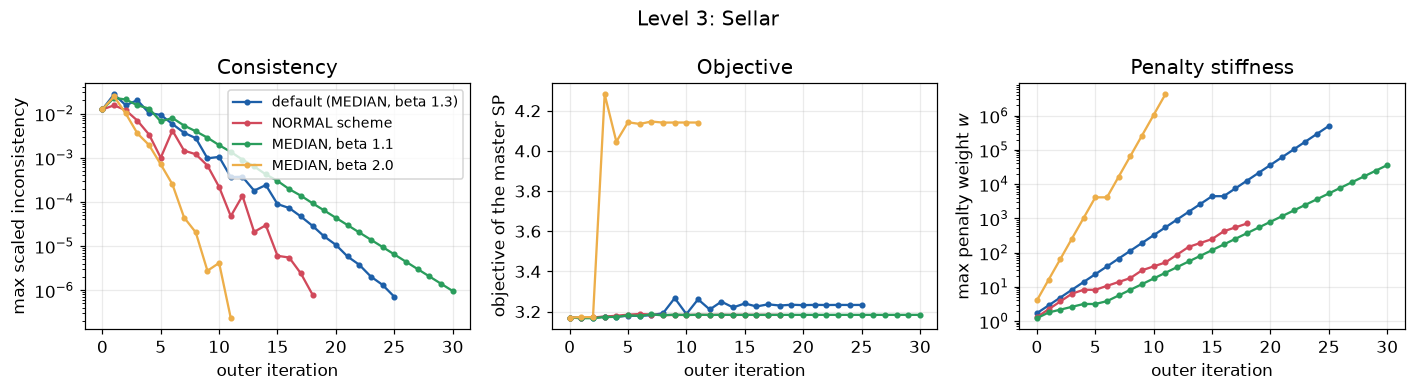

In [20]:
plot_histories(sellar_runs, "Level 3: Sellar")

---
# Level 4: three disciplines in a ring

Real systems have more than two disciplines, and their coupling is rarely a simple
back-and-forth. Here is a problem with **three** disciplines coupled in a **ring**
(1 needs $b$ from 2, 2 needs $c$ from 3, 3 needs $a$ from 1) and one variable $u$ **shared by
all three**:

$$
\begin{aligned}
\min_{u, v, w, s}\ & u + v + s + a + b + c
\qquad \text{s.t.}\quad w + b - 10 \le 0, \quad c - 2 \le 0 \\
\text{where}\ & a = \log u + \log v + \log b, \qquad b = u^{-1} + w^{-1} + c^{-1}, \qquad
c = 0.5 + 0.3/a + (s - 1)^2 .
\end{aligned}
$$

The coupling structure, written as an **N2 matrix** (row: who sends, column: who receives):

In [21]:
pd.DataFrame([["discipline 1", "", "a"], ["b", "discipline 2", ""], ["", "c", "discipline 3"]],
             index=["D1", "D2", "D3"], columns=["D1", "D2", "D3"])

,D1,D2,D3
D1,discipline 1,,a
D2,b,discipline 2,
D3,,c,discipline 3


There is no natural "system level" here, which is exactly the situation NHATC was designed
for: each subproblem negotiates directly with the two others. First we compute a **reference**
with a monolithic IDF formulation (SLSQP, many random starts) so we can judge DMDO's answer.

In [22]:
def ring_a(u, v, b):
    return np.log(u) + np.log(v) + np.log(b)


def ring_b(u, w, c):
    return 1.0 / u + 1.0 / w + 1.0 / c


def ring_c(u, s, a):
    return 0.5 + 0.3 / a + (s - 1.0) ** 2


def ring_reference(n_starts=40, seed=1):
    """Monolithic IDF: z = [u, v, w, s, a_t, b_t, c_t] with equality constraints on the targets."""
    rng = np.random.default_rng(seed)
    obj = lambda z: z[0] + z[1] + z[3] + ring_a(z[0], z[1], z[5]) + ring_b(z[0], z[2], z[6]) + ring_c(z[0], z[3], z[4])
    cons = [{"type": "eq", "fun": lambda z: [z[4] - ring_a(z[0], z[1], z[5]), z[5] - ring_b(z[0], z[2], z[6]),
                                             z[6] - ring_c(z[0], z[3], z[4])]},
            {"type": "ineq", "fun": lambda z: 10.0 - z[2] - ring_b(z[0], z[2], z[6])},
            {"type": "ineq", "fun": lambda z: 2.0 - ring_c(z[0], z[3], z[4])}]
    best = None
    for _ in range(n_starts):
        z0 = np.r_[rng.uniform(0.5, 5, 4), rng.uniform(0.5, 4, 3)]
        r = minimize(obj, z0, method="SLSQP", bounds=[(1e-3, 10)] * 4 + [(0.1, 10)] * 3, constraints=cons,
                     options={"ftol": 1e-12, "maxiter": 500})
        if r.success and (best is None or r.fun < best.fun):
            best = r
    return best


ref = ring_reference()
F_REF_RING = ref.fun
print(f"reference: f* = {F_REF_RING:.5f} at u, v, w, s = {np.round(ref.x[:4], 4)}; a, b, c = {np.round(ref.x[4:], 4)}")

reference: f* = 5.96917 at u, v, w, s = [1.1998 0.781  8.452  0.3912]; a, b, c = [0.372  1.548  1.6771]


Now the DMDO model. Two new things in the table:

- a variable shared by **several** subproblems has a **list** of links: SP 1's copy of $u$ is
  linked to the copies in SP 2 and SP 3, `link = [2, 3]`;
- the objective is **split**: each subproblem carries the terms it computes ($u + v + a$ in
  SP 1, $b$ in SP 2, $s + c$ in SP 3), so that no subproblem has to guess another's output.

In [23]:
ring_table = pd.DataFrame(
    [("u", 1, [2, 3], "s", 1e-3, 1.0, 10.0),
     ("v", 1, None, "u", 1e-3, 1.0, 10.0),
     ("b", 1, 2, "fb", 0.1, 1.0, 10.0),
     ("a", 1, 3, "ff", 0.1, 1.0, 10.0),
     ("u", 2, [1, 3], "s", 1e-3, 1.0, 10.0),
     ("w", 2, None, "u", 1e-3, 1.0, 10.0),
     ("c", 2, 3, "fb", 0.1, 1.0, 10.0),
     ("b", 2, 1, "ff", 0.1, 1.0, 10.0),
     ("u", 3, [1, 2], "s", 1e-3, 1.0, 10.0),
     ("s", 3, None, "u", 1e-3, 1.0, 10.0),
     ("a", 3, 1, "fb", 0.1, 1.0, 10.0),
     ("c", 3, 2, "ff", 0.1, 1.0, 10.0)],
    columns=["name", "subproblem", "link", "coupling", "lb", "baseline", "ub"],
    index=pd.RangeIndex(1, 13, name="variable #"))


def ring_analysis_1(x):
    return [ring_a(*x)]              # x = [u, v, b]


def ring_analysis_2(x):
    return [ring_b(*x)]              # x = [u, w, c]


def ring_analysis_3(x):
    return [ring_c(*x)]              # x = [u, s, a]


def ring_objective_1(x, y, *args):
    u, v, b = x
    return [u + v + y[0], [0.0]]


def ring_objective_2(x, y, *args):
    u, w, c = x
    return [y[0], [w + y[0] - 10.0]]


def ring_objective_3(x, y, *args):
    u, s, a = x
    return [s + y[0], [y[0] - 2.0]]


RING_SPECS = [dict(index=1, inputs=[1, 2, 3], outputs=[4], analysis=ring_analysis_1, opt=ring_objective_1),
              dict(index=2, inputs=[5, 6, 7], outputs=[8], analysis=ring_analysis_2, opt=ring_objective_2),
              dict(index=3, inputs=[9, 10, 11], outputs=[12], analysis=ring_analysis_3, opt=ring_objective_3)]


def check_ring(mdo):
    x = values(mdo)
    u, v, w, s = x["u_1"], x["v_1"], x["w_2"], x["s_3"]
    a, b, c = ring_a(u, v, x["b_1"]), ring_b(u, w, x["c_2"]), ring_c(u, s, x["a_3"])
    f = u + v + s + a + b + c
    return {"f": f, "gap to reference": f - F_REF_RING, "g1 = w + b - 10": w + b - 10, "g2 = c - 2": c - 2,
            "max |target - response|": max(abs(a - x["a_3"]), abs(b - x["b_1"]), abs(c - x["c_2"])),
            "max |u copies|": max(abs(u - x["u_2"]), abs(u - x["u_3"]))}


ring_table

,name,subproblem,link,coupling,lb,baseline,ub
variable #,,,,,,,
1,u,1,"[2, 3]",s,0.001,1,10
2,v,1,None,u,0.001,1,10
3,b,1,2,fb,0.1,1,10
4,a,1,3,ff,0.1,1,10
5,u,2,"[1, 3]",s,0.001,1,10
6,w,2,None,u,0.001,1,10
7,c,2,3,fb,0.1,1,10
8,b,2,1,ff,0.1,1,10
9,u,3,"[1, 2]",s,0.001,1,10


In [24]:
rows, ring_runs = [], {}
for label, kw in {"scipy, default": {}, "scipy, beta 1.1": {"beta": 1.1}}.items():
    mdo = build_mdo(ring_table, RING_SPECS, budget=60, **kw)
    h, s = run(mdo, "ring")
    ring_runs[label] = h
    rows.append({"run": label, "outer iterations": len(h), "seconds": s, **check_ring(mdo)})
pd.DataFrame(rows).set_index("run")

,outer iterations,seconds,f,gap to reference,g1 = w + b - 10,g2 = c - 2,max |target - response|,max |u copies|
run,,,,,,,,
"scipy, default",26,5.69256,5.96931,0.000144553,-0.00653713,-0.326346,5.25942e-06,3.63349e-06
"scipy, beta 1.1",42,8.17905,5.96918,1.136e-05,-5.42858e-06,-0.322289,1.19059e-05,7.45165e-06


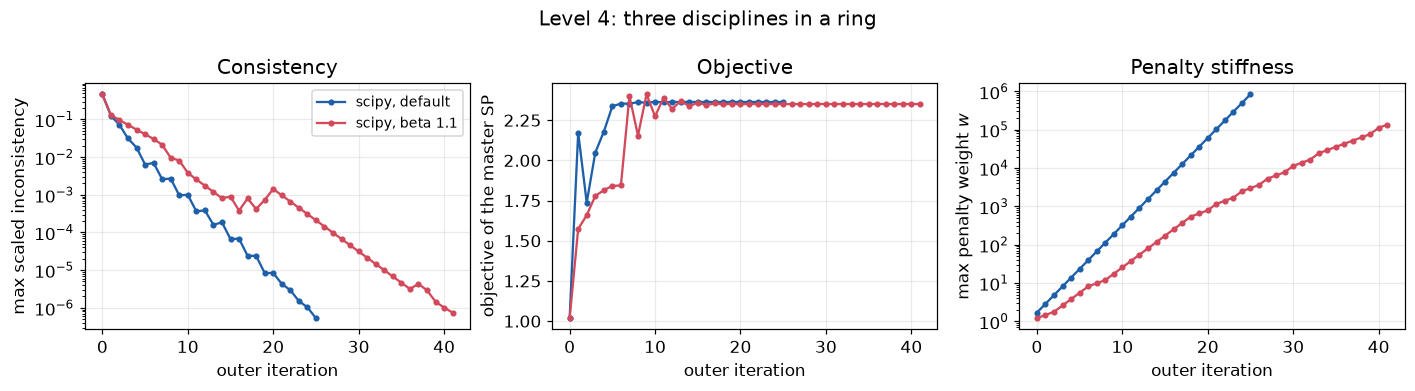

In [25]:
plot_histories(ring_runs, "Level 4: three disciplines in a ring")

DMDO matches the monolithic reference to about four digits, with every copy and target
consistent. Note that the "Objective" curve now shows only the **master** subproblem's share
($u + v + a$); `check_ring` adds up the three shares to get $f$.

> **Checkpoint 4.** (a) How many consistency constraints does this model have? (b) Why is the
> objective split instead of put entirely in SP 1?
>
> *Answers:* (a) Six: three for the copies of $u$ (1-2, 1-3, 2-3) and three for the coupling
> targets ($a$, $b$, $c$). (b) SP 1 does not compute $b$ or $c$; it would have to use its
> *targets* for them, which are only correct at convergence. Giving each term to the
> subproblem that computes it lets every subproblem see the true effect of its decisions.

---
# Level 5: describing a problem in a YAML file

For larger problems it is convenient to keep the model in a **YAML file** instead of Python
code, for example to share it or to run it from a terminal. `DMDO.main` reads such a file. Each
variable is one line `[name, subproblem, link, coupling, lb, baseline, ub, dim, type]`: the
compact table again. Analyses and objectives are referred to by **name**.

In [26]:
RUNNING_YAML = """
variables:
  # key: [name, subproblem, link, coupling, lb, baseline, ub, dim, type]
  v1: ["u", 1, 2,    s,  0.001, 1.0, 10.0, 1, "R"]
  v2: ["v", 1, None, u,  0.001, 1.0, 10.0, 1, "R"]
  v3: ["a", 1, 2,    ff, 0.1,   1.0, 10.0, 1, "R"]
  v4: ["b", 1, 2,    fb, 0.1,   1.0, 10.0, 1, "R"]
  v5: ["u", 2, 1,    s,  0.001, 1.0, 10.0, 1, "R"]
  v6: ["w", 2, None, u,  0.001, 1.0, 10.0, 1, "R"]
  v7: ["a", 2, 1,    fb, 0.1,   1.0, 10.0, 1, "R"]
  v8: ["b", 2, 1,    ff, 0.1,   1.0, 10.0, 1, "R"]
DA:
  DA1: {index: 1, inputs: [v1, v2, v4], outputs: [v3], blackbox: analysis_1, type: callable, links: 2, coupling_type: ff}
  DA2: {index: 2, inputs: [v5, v6, v7], outputs: [v8], blackbox: analysis_2, type: callable, links: 1, coupling_type: ff}
MDA:
  MDA1: {index: 1, nAnalyses: 1, analyses: [1], variables: [v1, v2, v4], responses: [v3]}
  MDA2: {index: 2, nAnalyses: 1, analyses: [2], variables: [v5, v6, v7], responses: [v8]}
coord:
  c1: {index: 1, type: ADMM, beta: 1.3, gamma: 0.5, nsp: 2, budget: 50, index_of_master_SP: 1,
       display: False, scaling: None, mode: serial, M_update_scheme: median, store_q_io: False}
subproblem:
  sp1: {nv: 3, index: 1, vars: [v1, v2, v4], resps: [v3], is_main: True, MDA: 1, coordinator: 1,
        opt: objective_1, type: callable, fmin_nop: inf, budget: 150, display: False, solver: scipy,
        scipy: {method: SLSQP, options: {disp: False, maxiter: 200}, is_con: True, tol: 1.0e-8}}
  sp2: {nv: 3, index: 2, vars: [v5, v6, v7], resps: [v8], is_main: False, MDA: 2, coordinator: 1,
        opt: objective_2, type: callable, fmin_nop: inf, budget: 150, display: False, solver: scipy,
        scipy: {method: SLSQP, options: {disp: False, maxiter: 200}, is_con: True, tol: 1.0e-8}}
USER:
MDO:
  architecture: IDF
  coordinator: 1
  subproblems: [1, 2]
  responses: [v3, v8]
  fmin: inf
  hmin: inf
  display: True
  inc_stop: 1.0e-6
  stop: "Iteration budget exhausted"
  tab_inc: []
  noprogress_stop: 100
"""
yaml_file = os.path.join(WORK_DIR, "running_example.yaml")
with open(yaml_file, "w") as fh:
    fh.write(RUNNING_YAML)

Run `main` in **build** mode: it returns the assembled `MDO` without running it. Because the
YAML file can only store *names*, we then replace each name with the actual Python function.
(With `scaling: None`, DMDO scales each inconsistency by $0.1/(ub - lb)$.)

In [27]:
with contextlib.redirect_stdout(io.StringIO()):
    yaml_mdo = main({"setup_file": yaml_file, "run_mode": "build", "mdo_name": "running_yaml",
                     "working_dir": WORK_DIR})

CALLABLES = {"analysis_1": analysis_1, "analysis_2": analysis_2,
             "objective_1": objective_1, "objective_2": objective_2}
for sp in yaml_mdo.subProblems:
    for da in sp.MDA_process.analyses:
        da.blackbox = CALLABLES[da.blackbox]
    sp.opt = CALLABLES[sp.opt]

h, s = run(yaml_mdo, "yaml")
pd.Series(check_running(yaml_mdo)).to_frame("from YAML").T

,f,gap to reference,g = w + b - 10,|a - a target|,|b - b target|,|u_1 - u_2|,max inconsistency
from YAML,4.98999,0.000659157,-2.80465e-05,5.49891e-05,9.41441e-05,4.54024e-05,9.41441e-05


---
# Level 6: good practice, pitfalls and your own problem

## Checklist for a DMDO model

1. **Write the compact table first**, on paper. Every variable used by two subproblems appears
   once per subproblem; every coupling variable is `ff` where it is computed and `fb` where it
   is used.
2. **Give coupling variables meaningful bounds**: DMDO enforces them in the subproblem that
   computes the variable, and they keep the analyses in their valid range.
3. **Give each objective term to the subproblem that computes it.**
4. **Check `x`'s order**: `opt(x, y)` receives the subproblem's inputs in the order you
   listed them, and its analysis outputs in `y`.
5. **Start with `solver="scipy"`** if the physics is smooth; switch a subproblem to `mads` if its
   analysis is a noisy or crashing blackbox.
6. **Verify**: recompute the analyses at the final design, check every consistency constraint
   and every constraint, and compare with a reference when one exists.

## Things to know about DMDO 2604.0

- `MDO.run` **pickles** the whole problem at every outer iteration (for restarts). Analyses and
  objectives must therefore be ordinary named functions (no lambdas).
- Importing DMDO creates a `data/logs/...` folder in the current directory, and every run
  writes logs and checkpoints next to its `file`. That is why this notebook works in a
  temporary folder.
- The `Objective` column of the history is the **master** subproblem's objective only.
  Compute the full objective yourself.
- The penalty weights can grow very large (look at the "max w" plots). If a run stops on its
  budget with a large inconsistency, the result is not usable: change $\beta$, the update
  scheme, the scaling or the starting point.
- `mode="parallel"` runs the subproblems in separate processes. That requires the analyses to
  live in an importable `.py` module, so it does not work with functions defined in a notebook
  on Windows. Use `"serial"` in notebooks.

## Exercises

1. **Objective allocation (Sellar).** Move the term $e^{-y_2}$ from SP 1 to SP 2 (which computes
   $y_2$). Rerun Level 3 with the default settings. Does the result get closer to $f^*$?
2. **Mixed solvers.** In the ring problem, give SP 3 the `mads` solver and keep `scipy` for the
   others (build the subproblems by hand, as in Level 1). How do time and accuracy change?
3. **Coupling bounds.** Rerun the running example with lower bounds of $10^{-3}$ on $a$ and $b$
   instead of 0.1. What happens, and why? (Hint: the MDF notebook, Section 6.)
4. **Starting point.** Change the baseline of every variable in the ring problem to 3. Does
   DMDO still reach the reference? How many outer iterations does it need?
5. **Your own problem.** Take a coupled problem from your project (or the aerostructural wing
   from the lecture with simple models: lift $\propto$ twist, twist $\propto$ lift). Write its
   compact table, its analyses and objectives, and solve it with `build_mdo`. Compare with a
   monolithic IDF solution.

## Going further

The DMDO repository contains a realistic case, the **supersonic business jet** (SBJ) from the
slides, with four disciplines (aircraft, propulsion, aerodynamics, structures), 56 variables
and a YAML model (`tests/SBJ` in the
[DMDO repository](https://github.com/Ahmed-Bayoumy/DMDO)). After this tutorial you can read
that model line by line.

---
## Takeaways

1. A DMDO model is a **compact table** (one row per variable per subproblem, with link and
   coupling type), plus one analysis and one objective/constraint function per subproblem.
2. DMDO solves it with NHATC: each subproblem is optimized with SLSQP or OMADS, and an ADMM
   coordinator penalizes and drives every inconsistency to zero.
3. Subproblem solver, $\beta$ and the weight-update scheme trade speed for accuracy; bounds on
   coupling variables keep analyses valid.
4. A consistent result is not necessarily an optimal one: **always verify** against the
   original problem and a reference.